## Dependency

In [ ]:
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np
import os
import h5py

## Path

In [ ]:
dataset_path = os.getcwd()

In [ ]:
# Create a list of all .h5 files in the dataset_path
h5_files = [f for f in os.listdir(dataset_path) if f.endswith('.h5')]
print(f"Found {len(h5_files)} .h5 files:\nExample file names:{h5_files[:3]}")

# Open the first .h5 file in the list to inspect its contents
if h5_files:
    file_path = os.path.join(dataset_path, h5_files[25070])
    with h5py.File(file_path, 'r') as file:
        print("\nKeys for each file:", list(file.keys()))
        for key in file.keys():
            print(f"\nData type of {key}:", type(file[key][()]))
            print(f"Shape of {key}:", file[key].shape)
            print(f"Array dtype: {file[key].dtype}")
            print(f"Array max val: {np.max(file[key])}")
            print(f"Array min val: {np.min(file[key])}")
else:
    print("No .h5 files found in the dataset_path.")

Found 57195 .h5 files:



Example file names:['volume_100_slice_0.h5', 'volume_100_slice_1.h5', 'volume_100_slice_10.h5']







Keys for each file: ['image', 'mask']







Data type of image: <class 'numpy.ndarray'>



Shape of image: (240, 240, 4)



Array dtype: float64



Array max val: 4.755863264388587



Array min val: -0.5070322108800785







Data type of mask: <class 'numpy.ndarray'>



Shape of mask: (240, 240, 3)



Array dtype: uint8



Array max val: 1



Array min val: 0


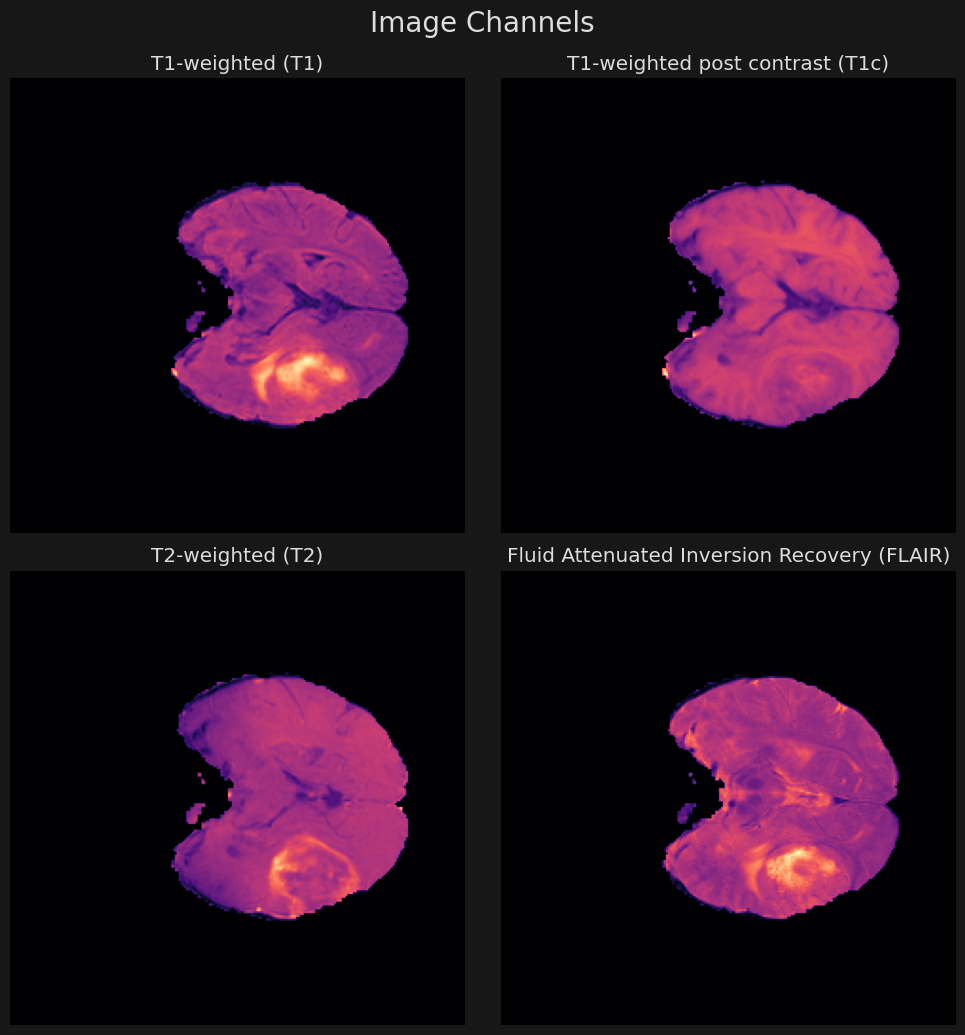

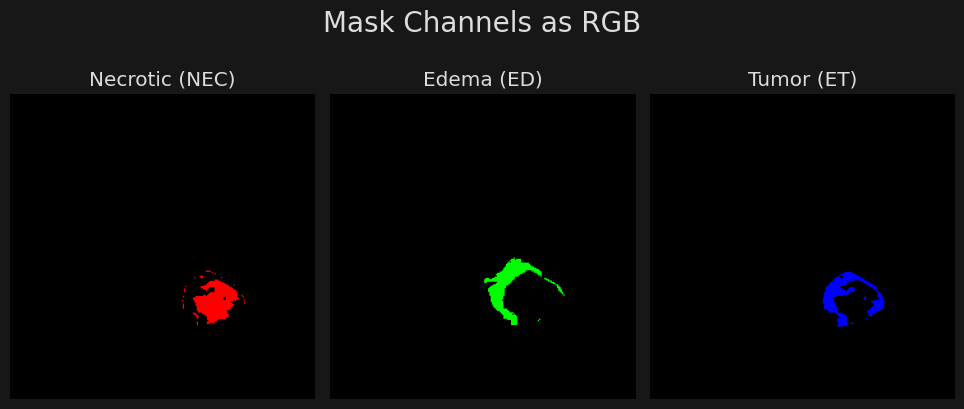

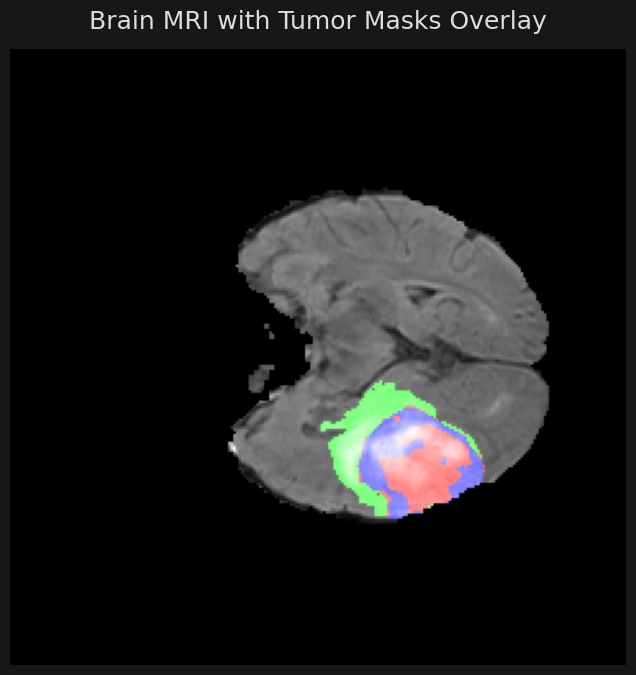

In [ ]:
plt.style.use('ggplot')
plt.rcParams['figure.facecolor'] = '#171717'
plt.rcParams['text.color']       = '#DDDDDD'

def display_image_channels(image, title='Image Channels'):
    channel_names = ['T1-weighted (T1)', 'T1-weighted post contrast (T1c)', 'T2-weighted (T2)', 'Fluid Attenuated Inversion Recovery (FLAIR)']
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    for idx, ax in enumerate(axes.flatten()):
        channel_image = image[idx, :, :]  # Transpose the array to display the channel
        ax.imshow(channel_image, cmap='magma')
        ax.axis('off')
        ax.set_title(channel_names[idx])
    plt.tight_layout()
    plt.suptitle(title, fontsize=20, y=1.03)
    plt.show()

def display_mask_channels_as_rgb(mask, title='Mask Channels as RGB'):
    channel_names = ['Necrotic (NEC)', 'Edema (ED)', 'Tumour (ET)']
    fig, axes = plt.subplots(1, 3, figsize=(9.75, 5))
    for idx, ax in enumerate(axes):
        rgb_mask = np.zeros((mask.shape[1], mask.shape[2], 3), dtype=np.uint8)
        rgb_mask[..., idx] = mask[idx, :, :] * 255  # Transpose the array to display the channel
        ax.imshow(rgb_mask)
        ax.axis('off')
        ax.set_title(channel_names[idx])
    plt.suptitle(title, fontsize=20, y=0.93)
    plt.tight_layout()
    plt.show()

def overlay_masks_on_image(image, mask, title='Brain MRI with Tumour Masks Overlay'):
    t1_image = image[0, :, :]  # Use the first channel of the image
    t1_image_normalized = (t1_image - t1_image.min()) / (t1_image.max() - t1_image.min())

    rgb_image = np.stack([t1_image_normalized] * 3, axis=-1)
    color_mask = np.stack([mask[0, :, :], mask[1, :, :], mask[2, :, :]], axis=-1)
    rgb_image = np.where(color_mask, color_mask, rgb_image)
    
    plt.figure(figsize=(8, 8))
    plt.imshow(rgb_image)
    plt.title(title, fontsize=18, y=1.02)
    plt.axis('off')
    plt.show()
    
    
# Sample image to view
sample_file_path = os.path.join(dataset_path, h5_files[25070])
data = {}
with h5py.File(sample_file_path, 'r') as file:
    for key in file.keys():
        data[key] = file[key][()]

# Transpose the image and mask to have channels first
image = data['image'].transpose(2, 0, 1)
mask = data['mask'].transpose(2, 0, 1)

# View images using plotting functions
display_image_channels(image)
display_mask_channels_as_rgb(mask)
overlay_masks_on_image(image, mask)

### Creating a Dataset and DataLoader

In [ ]:

class BrainScanDataset(Dataset):
    def __init__(self, file_paths, deterministic=False):
        self.file_paths = file_paths
        if deterministic:  # To always generate the same test images for consistency
            np.random.seed(1)
        np.random.shuffle(self.file_paths)
        
    def __len__(self):
        return len(self.file_paths)
    
    def __getitem__(self, idx):
        # Load h5 file, get image and mask
        file_path = self.file_paths[idx]
        with h5py.File(file_path, 'r') as file:
            image = file['image'][()]
            mask = file['mask'][()]
            
            # Reshape: (H, W, C) -> (C, H, W)
            image = image.transpose((2, 0, 1))
            mask = mask.transpose((2, 0, 1))
            
            # Adjusting pixel values for each channel in the image so they are between 0 and 255
            for i in range(image.shape[0]):    # Iterate over channels
                min_val = np.min(image[i])     # Find the min value in the channel
                image[i] = image[i] - min_val  # Shift values to ensure min is 0
                max_val = np.max(image[i]) + 1e-4     # Find max value to scale max to 1 now.
                image[i] = image[i] / max_val
            
            # Convert to float and scale the whole image
            image = torch.tensor(image, dtype=torch.float32)
            mask = torch.tensor(mask, dtype=torch.float32) 
            
        return image, mask

# Build .h5 file paths from dataset_path containing .h5 files
h5_files = [os.path.join(dataset_path, f) for f in os.listdir(dataset_path) if f.endswith('.h5')]
np.random.seed(42)
np.random.shuffle(h5_files)

# Split the dataset into train and validation sets (90:10)
split_idx = int(0.9 * len(h5_files))
train_files = h5_files[:split_idx]
val_files = h5_files[split_idx:]

# Create the train and val datasets
train_dataset = BrainScanDataset(train_files)
val_dataset = BrainScanDataset(val_files, deterministic=True)

# Sample dataloaders
train_dataloader = DataLoader(train_dataset, batch_size=5, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=5, shuffle=False)

# Use this to generate test images to view later
test_input_iterator = iter(DataLoader(val_dataset, batch_size=1, shuffle=False))

# Verifying dataloaders work
for images, masks in train_dataloader:
    print("Training batch - Images shape:", images.shape, "Masks shape:", masks.shape)
    break
for images, masks in val_dataloader:
    print("Validation batch - Images shape:", images.shape, "Masks shape:", masks.shape)
    break

Training batch - Images shape: torch.Size([5, 4, 240, 240]) Masks shape: torch.Size([5, 3, 240, 240])



Validation batch - Images shape: torch.Size([5, 4, 240, 240]) Masks shape: torch.Size([5, 3, 240, 240])


## The UNet Architecture

In [ ]:
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        self.encoder_block = nn.Sequential(
            nn.Conv2d(in_channels,  out_channels, kernel_size=(3,3), stride=1, padding=1),
            activation,
            nn.Conv2d(out_channels, out_channels, kernel_size=(3,3), stride=1, padding=1),
            activation
        )
    def forward(self, x):
        return self.encoder_block(x)
    
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        self.decoder_block = nn.Sequential(
            nn.Conv2d(in_channels,  in_channels//2, kernel_size=(3,3), stride=1, padding=1),
            activation,
            nn.Conv2d(in_channels//2, out_channels, kernel_size=(3,3), stride=1, padding=1),
            activation
        )
    def forward(self, x):
        return self.decoder_block(x)

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Config
        in_channels  = 4   # Input images have 4 channels
        out_channels = 3   # Mask has 3 channels
        n_filters    = 32  # Scaled down from 64 in original paper
        activation   = nn.ReLU()
        
        # Up and downsampling methods
        self.downsample  = nn.MaxPool2d((2,2), stride=2)
        self.upsample    = nn.UpsamplingBilinear2d(scale_factor=2)
        
        # Encoder
        self.enc_block_1 = EncoderBlock(in_channels, 1*n_filters, activation)
        self.enc_block_2 = EncoderBlock(1*n_filters, 2*n_filters, activation)
        self.enc_block_3 = EncoderBlock(2*n_filters, 4*n_filters, activation)
        self.enc_block_4 = EncoderBlock(4*n_filters, 8*n_filters, activation)
        
        # Bottleneck
        self.bottleneck  = nn.Sequential(
            nn.Conv2d( 8*n_filters, 16*n_filters, kernel_size=(3,3), stride=1, padding=1),
            activation,
            nn.Conv2d(16*n_filters,  8*n_filters, kernel_size=(3,3), stride=1, padding=1),
            activation
        )
        
        # Decoder
        self.dec_block_4 = DecoderBlock(16*n_filters, 4*n_filters, activation)
        self.dec_block_3 = DecoderBlock( 8*n_filters, 2*n_filters, activation)
        self.dec_block_2 = DecoderBlock( 4*n_filters, 1*n_filters, activation)
        self.dec_block_1 = DecoderBlock( 2*n_filters, 1*n_filters, activation)
        
        # Output projection
        self.output      = nn.Conv2d(1*n_filters,  out_channels, kernel_size=(1,1), stride=1, padding=0)

        
    def forward(self, x):
        # Encoder
        skip_1 = self.enc_block_1(x)
        x      = self.downsample(skip_1)
        skip_2 = self.enc_block_2(x)
        x      = self.downsample(skip_2)
        skip_3 = self.enc_block_3(x)
        x      = self.downsample(skip_3)
        skip_4 = self.enc_block_4(x)
        x      = self.downsample(skip_4)
        
        # Bottleneck
        x      = self.bottleneck(x)
        
        # Decoder
        x      = self.upsample(x)
        x      = torch.cat((x, skip_4), axis=1)  # Skip connection
        x      = self.dec_block_4(x)
        x      = self.upsample(x)
        x      = torch.cat((x, skip_3), axis=1)  # Skip connection
        x      = self.dec_block_3(x)
        x      = self.upsample(x)
        x      = torch.cat((x, skip_2), axis=1)  # Skip connection
        x      = self.dec_block_2(x)
        x      = self.upsample(x)
        x      = torch.cat((x, skip_1), axis=1)  # Skip connection
        x      = self.dec_block_1(x)
        x      = self.output(x)
        return x
    
# Function to count number of parameters in a model for comparisons later
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    print(f'Total Parameters: {total_params:,}\n')

# Function that saves a model to specified path
def save_model(model, path='model_weights.pth'):
    torch.save(model.state_dict(), path)

### Training Loop
The code in the cell below defines and executes the training loop for our UNet models. 

The training process involves:
- Setting up the model and training configuration.
- Initialising the model and moving it to the chosen device.
- Adam optimizer for parameter updates and binary cross-entropy loss as the loss function.
- We then iterate through each epoch, we can optionally dynamically adjust the learning rate.

For each epoch, we conduct both training and validation steps:
- In the training step, we feed batches of data to the model, computes the loss, and updates the model parameters.
- In the validation step, we evaluate the model on a separate dataset to monitor performance without updating model parameters.
- We track and print out the average training and validation losses for each epoch, providing insights into the model's learning progress.

Finally, the function returns lists of training and validation losses for further analysis or plotting.

In [5]:
def train_model(model, train_dataloader, val_dataloader, config, verbose=True):
    device = config['device']
    n_epochs = config['n_epochs']
    learning_rate = config['learning_rate']
    batches_per_epoch = config['batches_per_epoch']
    lr_decay_factor = config['lr_decay_factor']

    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.BCEWithLogitsLoss()

    train_epoch_losses = []
    val_epoch_losses = []
    
    print("Training...")
    for epoch in range(1, n_epochs + 1):
        # Decay learning rate
        current_lr = learning_rate * (lr_decay_factor ** (epoch - 1))
        for param_group in optimizer.param_groups:
            param_group['lr'] = current_lr

        # Training step
        model.train()
        train_epoch_loss = 0
        for train_batch_idx, (train_inputs, train_targets) in enumerate(train_dataloader, start=1):
            if verbose: print(f"\rTrain batch: {train_batch_idx}/{batches_per_epoch}, Avg batch loss: {train_epoch_loss/train_batch_idx:.6f}", end='')
            train_inputs = train_inputs.to(device)
            train_targets = train_targets.to(device)
            train_preds = model(train_inputs)
            train_batch_loss = loss_fn(train_preds, train_targets)
            train_epoch_loss += train_batch_loss.item()

            optimizer.zero_grad()
            train_batch_loss.backward()
            optimizer.step()

            if train_batch_idx >= batches_per_epoch:
                if verbose: print()
                break
        train_epoch_losses.append(train_epoch_loss)

        # Val step
        model.eval()
        val_epoch_loss = 0
        with torch.no_grad():
            for val_batch_idx, (val_inputs, val_targets) in enumerate(val_dataloader, start=1):
                if verbose: print(f"\rVal batch: {val_batch_idx}/{batches_per_epoch}, Avg batch loss: {val_epoch_loss/val_batch_idx:.6f}", end='')
                val_inputs = val_inputs.to(device)
                val_targets = val_targets.to(device)
                val_preds = model(val_inputs)
                val_batch_loss = loss_fn(val_preds, val_targets)
                val_epoch_loss += val_batch_loss.item()
                
                if val_batch_idx >= batches_per_epoch:
                    if verbose: print()
                    break
        val_epoch_losses.append(val_epoch_loss)

        if verbose: print(f"Epoch: {epoch}, Train loss: {train_epoch_loss:.6f}, Val loss: {val_epoch_loss:.6f}, lr {current_lr:.6f}\n")
        
    print("Training complete.")
    return train_epoch_losses, val_epoch_losses

In [6]:
# Settings for training
train_config = {
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'n_epochs':          12,
    'batch_size':        32,
    'learning_rate':     1e-3,
    'batches_per_epoch': 50,
    'lr_decay_factor':   1
}

# Create UNet model and count params
model = UNet()
count_parameters(model)

# Create dataloaders
train_dataloader = DataLoader(train_dataset, batch_size=train_config['batch_size'], shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=train_config['batch_size'], shuffle=False)

# Train model
train_epoch_losses, val_epoch_losses = train_model(model, train_dataloader, val_dataloader, train_config, verbose=False)

Total Parameters: 5,496,451







Training starting...



Training complete.


### Learning Curves
Here we visualise the training and validation loss over each epoch, helping assess the model's learning progress and identify overfitting.

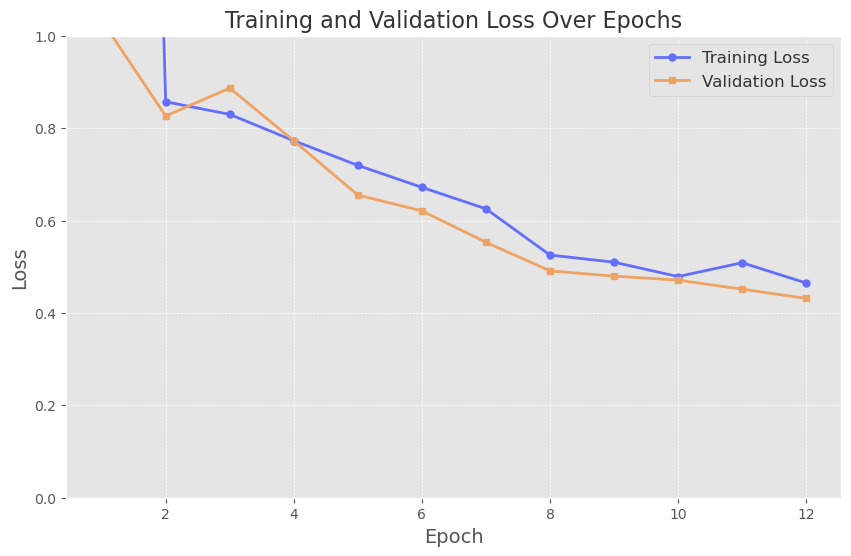

In [7]:
def plot_learning_curves(train_epoch_losses, val_epoch_losses):
    plt.style.use('ggplot')
    plt.rcParams['text.color'] = '#333333'

    fig, axis = plt.subplots(1, 1, figsize=(10, 6))

    # Plot training and validation loss (NaN is used to offset epochs by 1)
    axis.plot([np.NaN] + train_epoch_losses, color='#636EFA', marker='o', linestyle='-', linewidth=2, markersize=5, label='Training Loss')
    axis.plot([np.NaN] + val_epoch_losses,   color='#EFA363', marker='s', linestyle='-', linewidth=2, markersize=5, label='Validation Loss')

    # Adding title, labels and formatting
    axis.set_title('Training and Validation Loss Over Epochs', fontsize=16)
    axis.set_xlabel('Epoch', fontsize=14)
    axis.set_ylabel('Loss', fontsize=14)

    axis.set_ylim(0, 1)
    
    axis.legend(fontsize=12)
    axis.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.show()
    
plot_learning_curves(train_epoch_losses, val_epoch_losses)

### Viewing a Sample Prediction
This code demonstrates the model's performance on a test sample by displaying the input brain MRI images, the model's predicted mask, and the actual mask (ground truth).

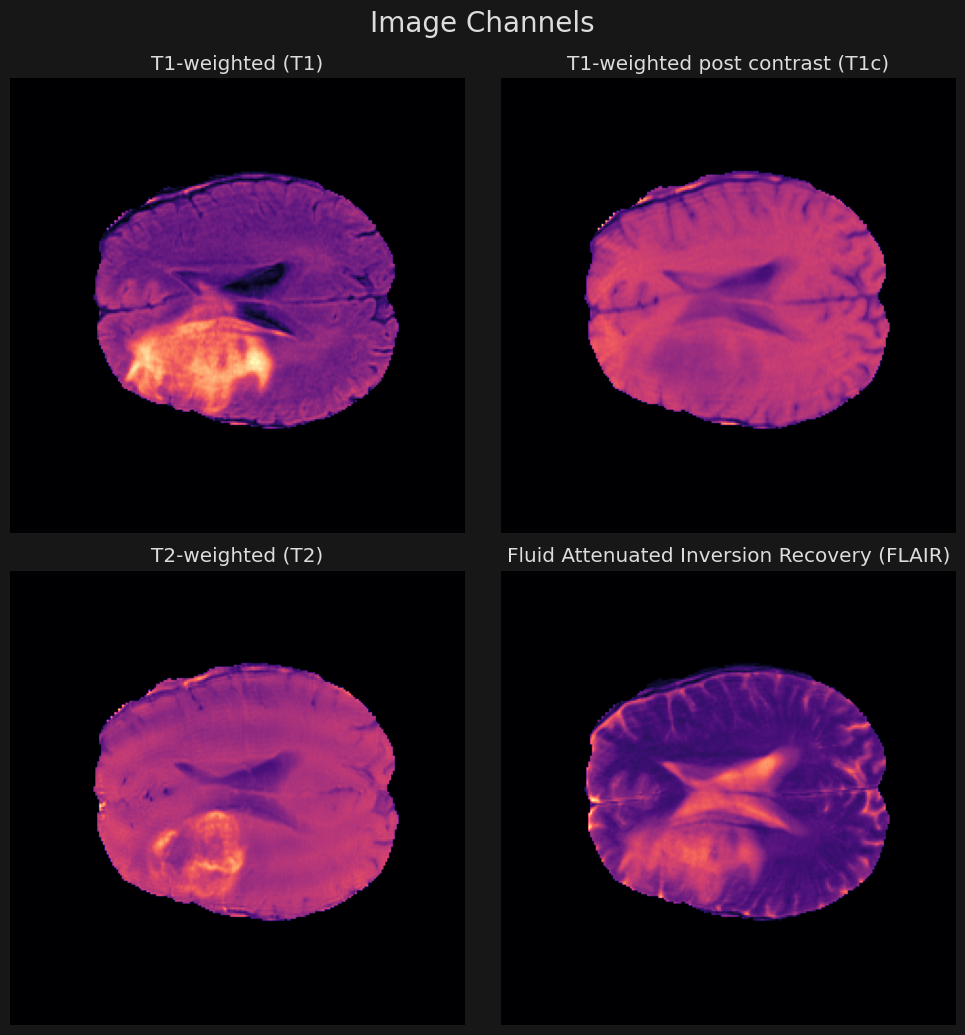

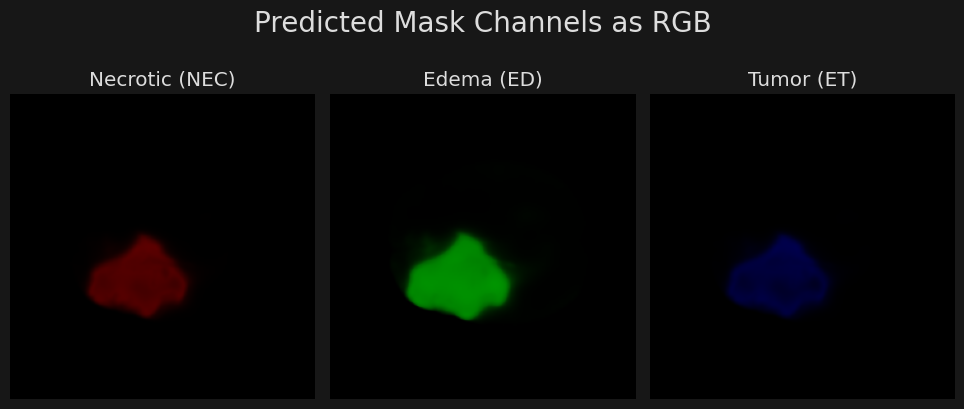

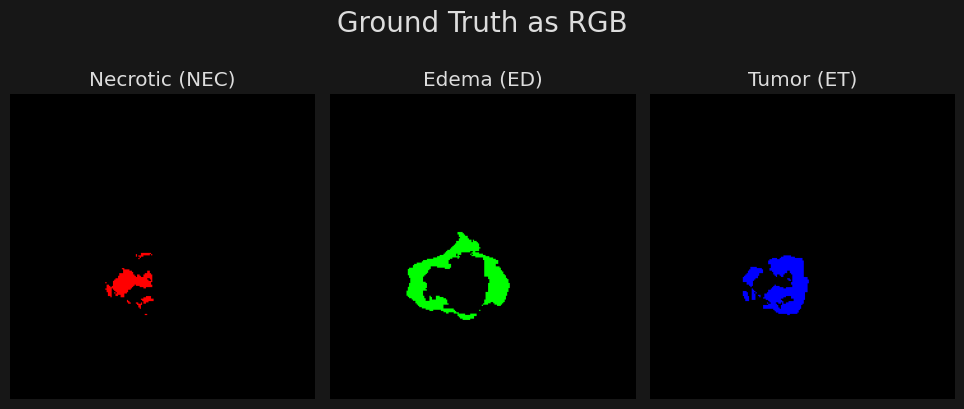

In [8]:
def display_test_sample(model, test_input, test_target, device):
    test_input, test_target = test_input.to(device), test_target.to(device)

    # Obtain the model's prediction
    test_pred = torch.sigmoid(model(test_input))

    # Process the image and masks for visualization
    image = test_input.detach().cpu().numpy().squeeze(0)
    mask_pred = test_pred.detach().cpu().numpy().squeeze(0)
    mask_target = test_target.detach().cpu().numpy().squeeze(0)

    # Set the plot aesthetics
    plt.rcParams['figure.facecolor'] = '#171717'
    plt.rcParams['text.color']       = '#DDDDDD'

    # Display the input image, predicted mask, and target mask
    display_image_channels(image)
    display_mask_channels_as_rgb(mask_pred, title='Predicted Mask Channels as RGB')
    display_mask_channels_as_rgb(mask_target, title='Ground Truth as RGB')
    

# Set so model and these images are on the same device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
    
# Get an image from the validation dataset that the model hasn't been trained on
test_input, test_target = next(test_input_iterator)

display_test_sample(model, test_input, test_target, device)

#### Thoughts:
- We trained our model for 12 epochs, where each epoch consisted of 50 batches of 32 images, for approximately 20,000 images out of the total training set of 55,000.
- The model appears to perform reasonably on the validation set, but not spectacularly. Unable to clearly segment separate tumourous regions, it's only able to identify the general region the tumour should be in, but not the different parts.


In [9]:
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        expansion_ratio = 4
        
        self.encoder_block = nn.Sequential(
            # ConvNeXt style blocks
            nn.Conv2d(in_channels,                   in_channels, kernel_size=(7,7), stride=1, padding=3, groups=in_channels),
            nn.BatchNorm2d(in_channels),
            nn.Conv2d(in_channels,  expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels, out_channels, kernel_size=(1,1), stride=1),
            
            nn.Conv2d(out_channels,                 out_channels, kernel_size=(7,7), stride=1, padding=3, groups=out_channels),
            nn.BatchNorm2d(out_channels),
            nn.Conv2d(out_channels, expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels, out_channels, kernel_size=(1,1), stride=1),
        )
    def forward(self, x):
        return self.encoder_block(x)
    
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        expansion_ratio = 4
        
        self.decoder_block = nn.Sequential(
            nn.Conv2d(in_channels,                    in_channels, kernel_size=(7,7), stride=1, padding=3, groups=in_channels),
            nn.BatchNorm2d(in_channels),
            nn.Conv2d(in_channels,    expansion_ratio*in_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*in_channels,   out_channels, kernel_size=(1,1), stride=1),
            
            nn.Conv2d(out_channels,                  out_channels, kernel_size=(7,7), stride=1, padding=3, groups=out_channels),
            nn.BatchNorm2d(out_channels),
            nn.Conv2d(out_channels,  expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels,  out_channels, kernel_size=(1,1), stride=1),
        )
    def forward(self, x):
        return self.decoder_block(x)
    

class UNet2(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Config
        in_channels  = 4   # Input images have 4 channels
        out_channels = 3   # Mask has 3 channels
        n_filters    = 32  # Scaled down from 64 in original paper
        activation   = nn.ReLU()
        
        # Up and downsampling methods
        self.downsample  = nn.MaxPool2d((2,2), stride=2)
        self.upsample    = nn.UpsamplingBilinear2d(scale_factor=2)
        
        # Encoder
        self.enc_block_1 = EncoderBlock(in_channels, 1*n_filters, activation)
        self.enc_block_2 = EncoderBlock(1*n_filters, 2*n_filters, activation)
        self.enc_block_3 = EncoderBlock(2*n_filters, 4*n_filters, activation)
        self.enc_block_4 = EncoderBlock(4*n_filters, 8*n_filters, activation)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),

            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),
        )
        
        # Decoder
        self.dec_block_4 = DecoderBlock(8*n_filters, 4*n_filters, activation)
        self.dec_block_3 = DecoderBlock(4*n_filters, 2*n_filters, activation)
        self.dec_block_2 = DecoderBlock(2*n_filters, 1*n_filters, activation)
        self.dec_block_1 = DecoderBlock(1*n_filters, 1*n_filters, activation)
        
        # Output projection
        self.output      = nn.Conv2d(1*n_filters,  out_channels, kernel_size=(1,1), stride=1, padding=0)

    def forward(self, x):
        # Encoder
        skip_1 = self.enc_block_1(x)
        x      = self.downsample(skip_1)
        skip_2 = self.enc_block_2(x)
        x      = self.downsample(skip_2)
        skip_3 = self.enc_block_3(x)
        x      = self.downsample(skip_3)
        skip_4 = self.enc_block_4(x)
        x      = self.downsample(skip_4)
        
        # Bottleneck
        x      = self.bottleneck(x)
        
        # Decoder
        x      = self.upsample(x)
        x      = torch.add(x, skip_4)  # Skip connection
        x      = self.dec_block_4(x)
        x      = self.upsample(x)
        x      = torch.add(x, skip_3)  # Skip connection
        x      = self.dec_block_3(x)
        x      = self.upsample(x)
        x      = torch.add(x, skip_2)  # Skip connection
        x      = self.dec_block_2(x)
        x      = self.upsample(x)
        x      = torch.add(x, skip_1)  # Skip connection
        x      = self.dec_block_1(x)
        x      = self.output(x)
        return x

### Training Loop
Identical to the previous one, only with learning rate decay.

Total Parameters: 3,082,739







Training starting...



Training complete.


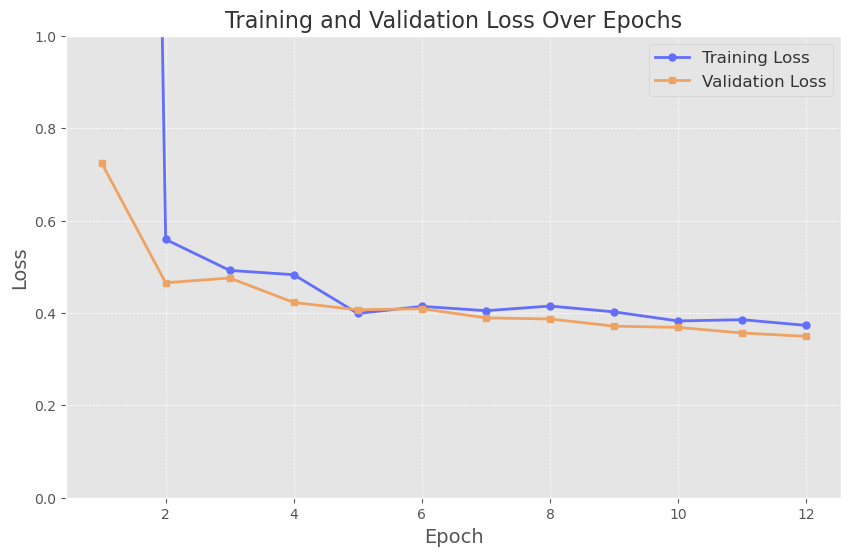

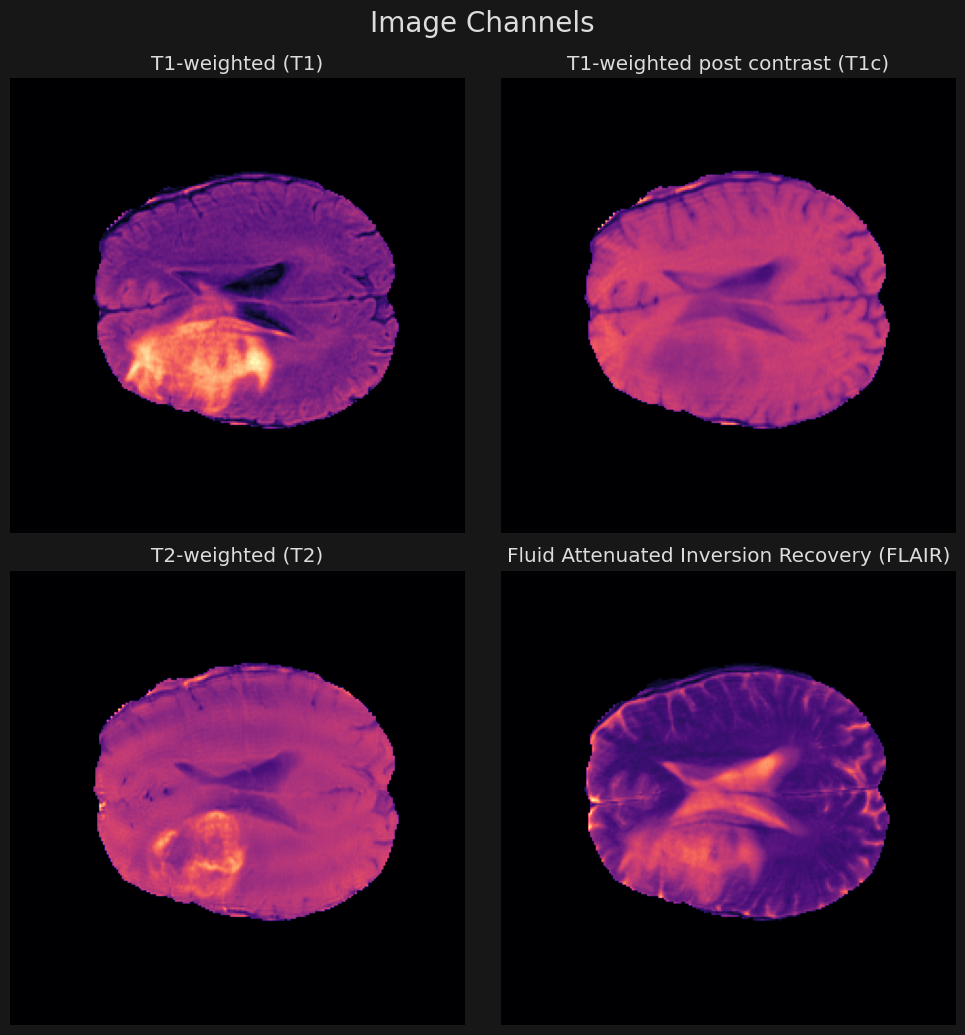

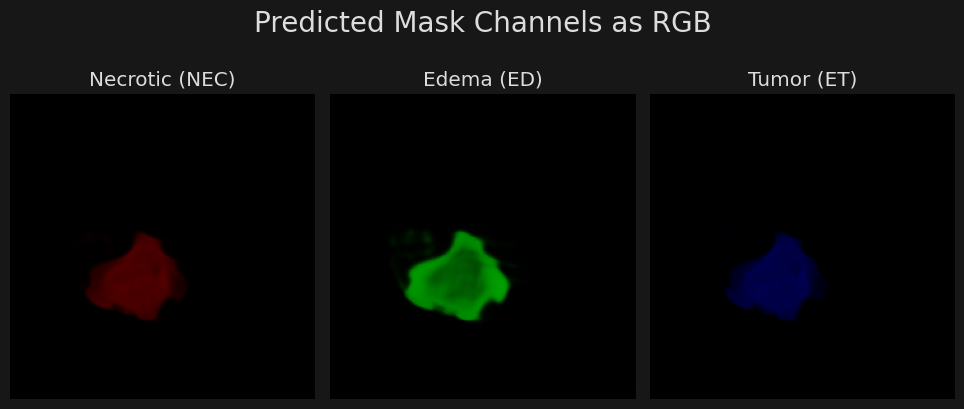

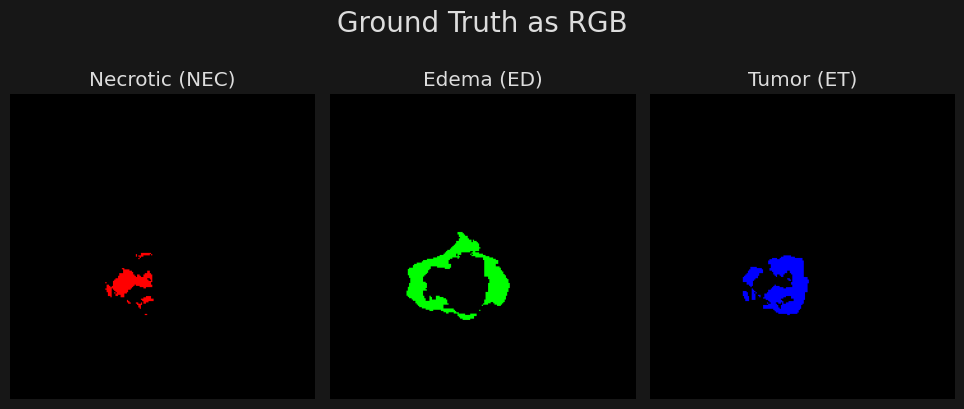

In [10]:
# Delete old model and clear GPU cache to release memory
del model
torch.cuda.empty_cache()

# Settings for training
train_config = {
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'n_epochs':          12,
    'batch_size':        32,
    'learning_rate':     1e-3,
    'batches_per_epoch': 50,
    'lr_decay_factor':   0.85
}

# Create UNet model and count params
model = UNet2()
count_parameters(model)

# Train model
train_epoch_losses, val_epoch_losses = train_model(model, train_dataloader, val_dataloader, train_config, verbose=False)

# Plot learning curves
plot_learning_curves(train_epoch_losses, val_epoch_losses)

# Performance on test image
display_test_sample(model, test_input, test_target, device)

#### Thoughts:
- We reduced the number of parameters in our model from ~5.5 million to ~3 million.
- Despite the reduced model size, our validation loss is less than the previous model's.
- Visualising our model's output, the improvement in performance is clear. The edges are sharper, and the model is beginning to distinguish between different parts of the tumour.

## Attention UNet

In [16]:
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        expansion_ratio = 4
        
        self.encoder_block = nn.Sequential(
            nn.Conv2d(in_channels,                   in_channels, kernel_size=(7,7), stride=1, padding=3, groups=in_channels),
            nn.BatchNorm2d(in_channels),
            nn.Conv2d(in_channels,  expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels, out_channels, kernel_size=(1,1), stride=1),
            
            nn.Conv2d(out_channels,                 out_channels, kernel_size=(7,7), stride=1, padding=3, groups=out_channels),
            nn.BatchNorm2d(out_channels),
            nn.Conv2d(out_channels, expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels, out_channels, kernel_size=(1,1), stride=1),
        )
    def forward(self, x):
        return self.encoder_block(x)
    
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, activation=nn.ReLU()):
        super().__init__()
        expansion_ratio = 4
        
        self.decoder_block = nn.Sequential(
            nn.Conv2d(in_channels,                    in_channels, kernel_size=(7,7), stride=1, padding=3, groups=in_channels),
            nn.BatchNorm2d(in_channels),
            nn.Conv2d(in_channels,    expansion_ratio*in_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*in_channels,   out_channels, kernel_size=(1,1), stride=1),
            
            nn.Conv2d(out_channels,                  out_channels, kernel_size=(7,7), stride=1, padding=3, groups=out_channels),
            nn.BatchNorm2d(out_channels),
            nn.Conv2d(out_channels,  expansion_ratio*out_channels, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(expansion_ratio*out_channels,  out_channels, kernel_size=(1,1), stride=1),
        )
    def forward(self, x):
        return self.decoder_block(x)
    
class AttentionResBlock(nn.Module):
    def __init__(self, in_channels, activation=nn.ReLU()):
        super().__init__()
        self.query_conv     = nn.Conv2d(in_channels, in_channels, kernel_size=(1,1), stride=1)
        self.key_conv       = nn.Conv2d(in_channels, in_channels, kernel_size=(1,1), stride=2)
        self.attention_conv = nn.Conv2d(in_channels, 1, kernel_size=(1,1), stride=1)
        
        self.upsample       = nn.UpsamplingBilinear2d(scale_factor=2)
        self.activation     = activation
    
    def forward(self, query, key, value):
        query = self.query_conv(query)
        key   = self.key_conv(key)
        
        combined_attention = self.activation(query + key)
        attention_map = torch.sigmoid(self.attention_conv(combined_attention))
        upsampled_attention_map = self.upsample(attention_map)
        attention_scores = value * upsampled_attention_map
        return attention_scores
        

class AttentionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Config
        in_channels  = 4   # Input images have 4 channels
        out_channels = 3   # Mask has 3 channels
        n_filters    = 32  # Scaled down from 64 in original paper
        activation   = nn.ReLU()
        
        # Up and downsampling methods
        self.downsample  = nn.MaxPool2d((2,2), stride=2)
        self.upsample    = nn.UpsamplingBilinear2d(scale_factor=2)
        
        # Encoder
        self.enc_block_1 = EncoderBlock(in_channels, 1*n_filters, activation)
        self.enc_block_2 = EncoderBlock(1*n_filters, 2*n_filters, activation)
        self.enc_block_3 = EncoderBlock(2*n_filters, 4*n_filters, activation)
        self.enc_block_4 = EncoderBlock(4*n_filters, 8*n_filters, activation)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),

            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),
        )
        
        # Decoder
        self.dec_block_4 = DecoderBlock(8*n_filters, 4*n_filters, activation)
        self.dec_block_3 = DecoderBlock(4*n_filters, 2*n_filters, activation)
        self.dec_block_2 = DecoderBlock(2*n_filters, 1*n_filters, activation)
        self.dec_block_1 = DecoderBlock(1*n_filters, 1*n_filters, activation)
        
        # Output projection
        self.output      = nn.Conv2d(1*n_filters,  out_channels, kernel_size=(1,1), stride=1, padding=0)
        
        # Attention res blocks
        self.att_res_block_1 = AttentionResBlock(1*n_filters)
        self.att_res_block_2 = AttentionResBlock(2*n_filters)
        self.att_res_block_3 = AttentionResBlock(4*n_filters)
        self.att_res_block_4 = AttentionResBlock(8*n_filters)

    def forward(self, x):
        # Encoder
        enc_1 = self.enc_block_1(x)
        x     = self.downsample(enc_1)
        enc_2 = self.enc_block_2(x)
        x     = self.downsample(enc_2)
        enc_3 = self.enc_block_3(x)
        x     = self.downsample(enc_3)
        enc_4 = self.enc_block_4(x)
        x     = self.downsample(enc_4)
        
        # Bottleneck
        dec_4 = self.bottleneck(x)
        
        # Decoder
        x     = self.upsample(dec_4)
        att_4 = self.att_res_block_4(dec_4, enc_4, enc_4)  # QKV
        x     = torch.add(x, att_4)  # Add attention masked value rather than concat
        
        dec_3 = self.dec_block_4(x)
        x     = self.upsample(dec_3)
        att_3 = self.att_res_block_3(dec_3, enc_3, enc_3)
        x     = torch.add(x, att_3)  # Add attention
        
        dec_2 = self.dec_block_3(x)
        x     = self.upsample(dec_2)
        att_2 = self.att_res_block_2(dec_2, enc_2, enc_2)
        x     = torch.add(x, att_2)  # Add attention
        
        dec_1 = self.dec_block_2(x)
        x     = self.upsample(dec_1)
        att_1 = self.att_res_block_1(dec_1, enc_1, enc_1)
        x     = torch.add(x, att_1)  # Add attention
        
        x     = self.dec_block_1(x)
        x     = self.output(x)
        return x

### Training Loop
In this training loop we increase the number of epochs to 25 and slightly increase the learning rate decay constant to accommodate for this greater number of epochs.

Total Parameters: 3,258,263







Training starting...



Training complete.


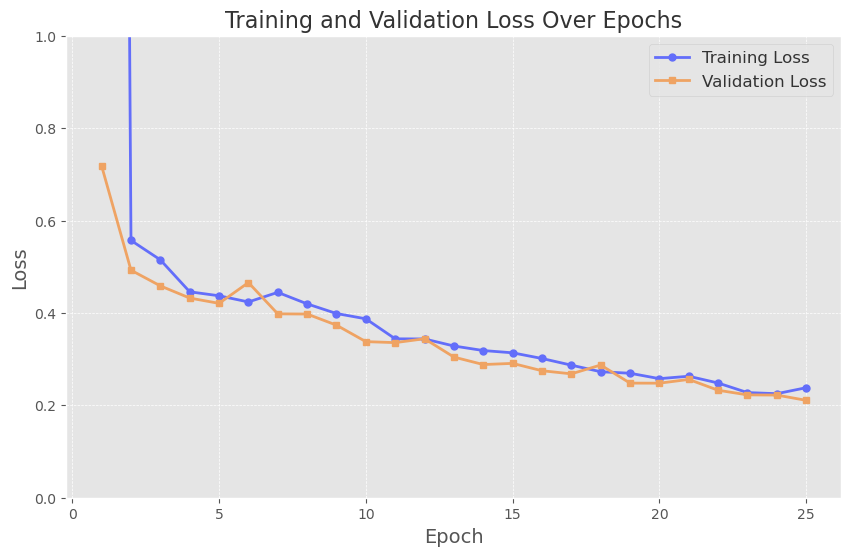

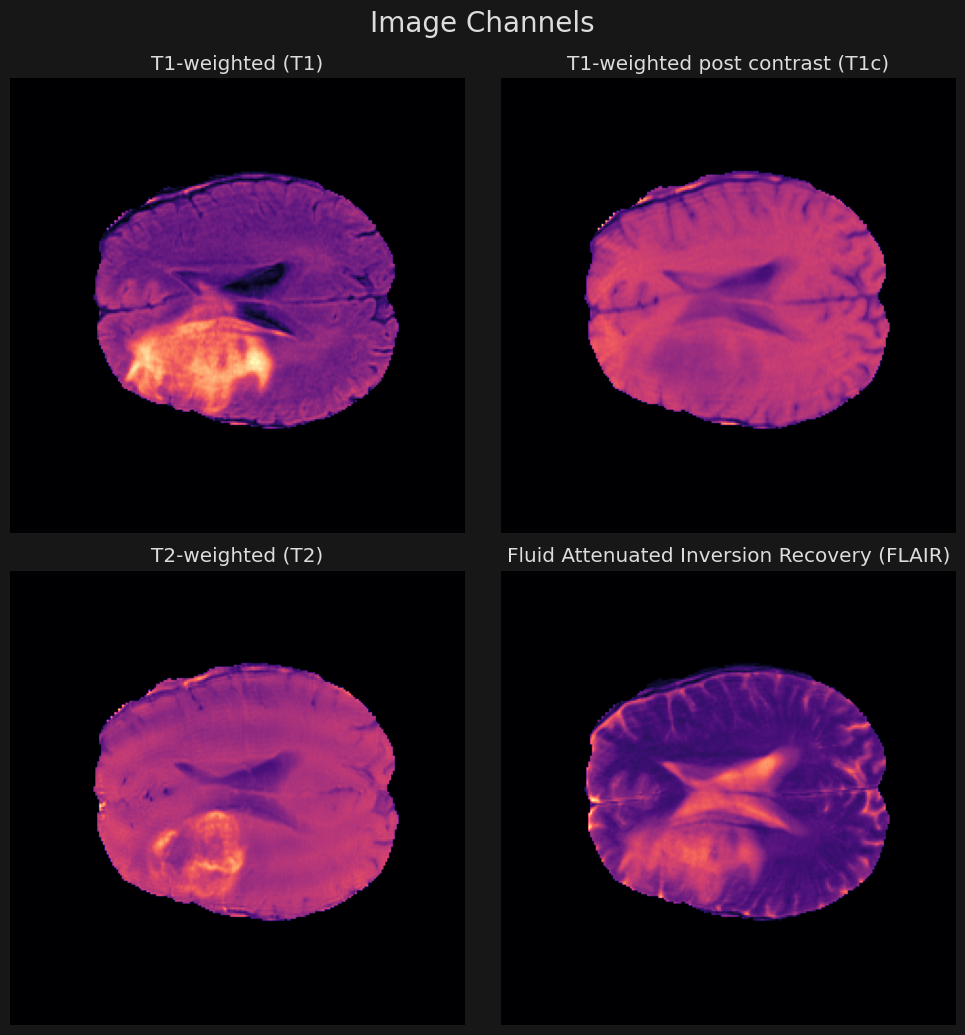

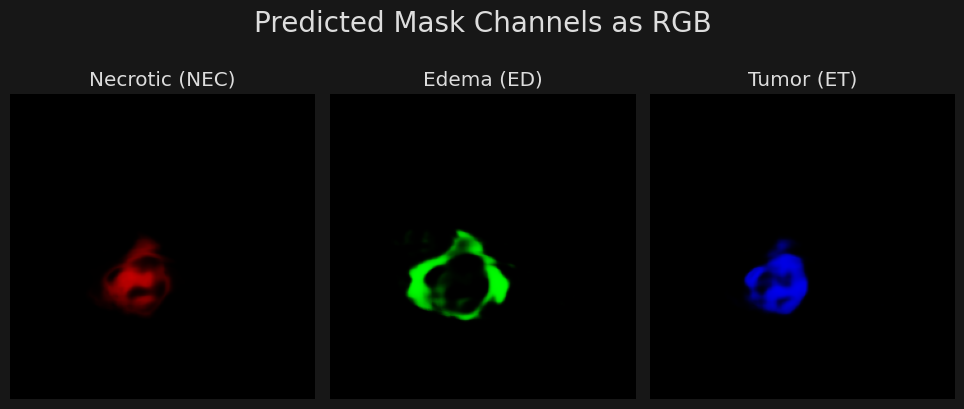

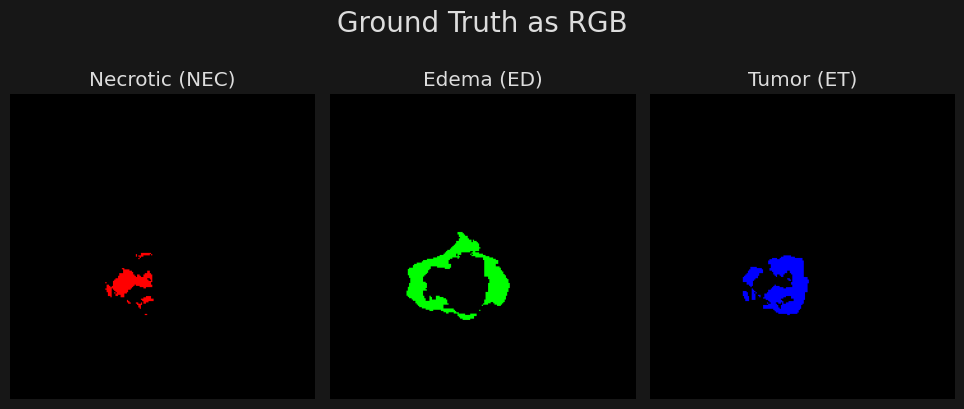

In [17]:
# Delete old model and clear GPU cache to release memory
del model
torch.cuda.empty_cache()

# Settings for training
train_config = {
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'n_epochs':          25,
    'batch_size':        32,
    'learning_rate':     1e-3,
    'batches_per_epoch': 50,
    'lr_decay_factor':   0.93
}

# Create UNet model and count params
model = AttentionUNet()
count_parameters(model)

# Train model
train_epoch_losses, val_epoch_losses = train_model(model, train_dataloader, val_dataloader, train_config, verbose=False)

# Save weights
save_model(model, 'attention-unet-weights.pth')

# Plot learning curves
plot_learning_curves(train_epoch_losses, val_epoch_losses)

# Performance on test image
display_test_sample(model, test_input, test_target, device)

#### Thoughts:
- This model has approximately the same number of parameters as before ~3 million.
- With the extra epochs, we have brought our validation loss down to half the orignal models. 
- The model's output is very impressive. The different regions are clearly separated and the model has achieved state of the art performance.

## Visualising Attention
We can easily visualise attention by modifying our code to return the attention mask during the forward pass, so we can plot it.

In [ ]:
class AttentionResBlock(nn.Module):
    def __init__(self, in_channels, activation=nn.ReLU()):
        super().__init__()
        self.query_conv     = nn.Conv2d(in_channels, in_channels, kernel_size=(1,1), stride=1)
        self.key_conv       = nn.Conv2d(in_channels, in_channels, kernel_size=(1,1), stride=2)
        self.attention_conv = nn.Conv2d(in_channels, 1, kernel_size=(1,1), stride=1)
        
        self.upsample       = nn.UpsamplingBilinear2d(scale_factor=2)
        self.activation     = activation
    
    def forward(self, query, key, value):
        query = self.query_conv(query)
        key   = self.key_conv(key)
        
        combined_attention = self.activation(query + key)
        attention_map = torch.sigmoid(self.attention_conv(combined_attention))
        upsampled_attention_map = self.upsample(attention_map)
        attention_scores = value * upsampled_attention_map
        return attention_scores, attention_map  # Additionally return attention map
        

class AttentionVisUNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        # Config
        in_channels  = 4   # Input images have 4 channels
        out_channels = 3   # Mask has 3 channels
        n_filters    = 32  # Scaled down from 64 in original paper
        activation   = nn.ReLU()
        
        # Up and downsampling methods
        self.downsample  = nn.MaxPool2d((2,2), stride=2)
        self.upsample    = nn.UpsamplingBilinear2d(scale_factor=2)
        
        # Encoder
        self.enc_block_1 = EncoderBlock(in_channels, 1*n_filters, activation)
        self.enc_block_2 = EncoderBlock(1*n_filters, 2*n_filters, activation)
        self.enc_block_3 = EncoderBlock(2*n_filters, 4*n_filters, activation)
        self.enc_block_4 = EncoderBlock(4*n_filters, 8*n_filters, activation)
        
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),

            nn.Conv2d(     8*n_filters,   8*n_filters, kernel_size=(7,7), stride=1, padding=3, groups=8*n_filters),
            nn.BatchNorm2d(8*n_filters),
            nn.Conv2d(     8*n_filters, 4*8*n_filters, kernel_size=(1,1), stride=1),
            activation,
            nn.Conv2d(   4*8*n_filters,   8*n_filters, kernel_size=(1,1), stride=1),
        )
        
        # Decoder
        self.dec_block_4 = DecoderBlock(8*n_filters, 4*n_filters, activation)
        self.dec_block_3 = DecoderBlock(4*n_filters, 2*n_filters, activation)
        self.dec_block_2 = DecoderBlock(2*n_filters, 1*n_filters, activation)
        self.dec_block_1 = DecoderBlock(1*n_filters, 1*n_filters, activation)
        
        # Output projection
        self.output      = nn.Conv2d(1*n_filters,  out_channels, kernel_size=(1,1), stride=1, padding=0)
        
        # Attention res blocks
        self.att_res_block_1 = AttentionResBlock(1*n_filters)
        self.att_res_block_2 = AttentionResBlock(2*n_filters)
        self.att_res_block_3 = AttentionResBlock(4*n_filters)
        self.att_res_block_4 = AttentionResBlock(8*n_filters)

    def forward(self, x):
        # Encoder
        enc_1 = self.enc_block_1(x)
        x     = self.downsample(enc_1)
        enc_2 = self.enc_block_2(x)
        x     = self.downsample(enc_2)
        enc_3 = self.enc_block_3(x)
        x     = self.downsample(enc_3)
        enc_4 = self.enc_block_4(x)
        x     = self.downsample(enc_4)
        
        # Bottleneck
        dec_4 = self.bottleneck(x)
        
        # Decoder
        x     = self.upsample(dec_4)
        att_4, map_4 = self.att_res_block_4(dec_4, enc_4, enc_4)  # Get attention maps
        x     = torch.add(x, att_4)  # Add attention masked value rather than concat
        
        dec_3 = self.dec_block_4(x)
        x     = self.upsample(dec_3)
        att_3, map_3 = self.att_res_block_3(dec_3, enc_3, enc_3)
        x     = torch.add(x, att_3)  # Add attention
        
        dec_2 = self.dec_block_3(x)
        x     = self.upsample(dec_2)
        att_2, map_2 = self.att_res_block_2(dec_2, enc_2, enc_2)
        x     = torch.add(x, att_2)  # Add attention
        
        dec_1 = self.dec_block_2(x)
        x     = self.upsample(dec_1)
        att_1, map_1 = self.att_res_block_1(dec_1, enc_1, enc_1)
        x     = torch.add(x, att_1)  # Add attention
        
        x     = self.dec_block_1(x)
        x     = self.output(x)
        return x, map_4, map_3, map_2, map_1  # Return attention maps for plotting

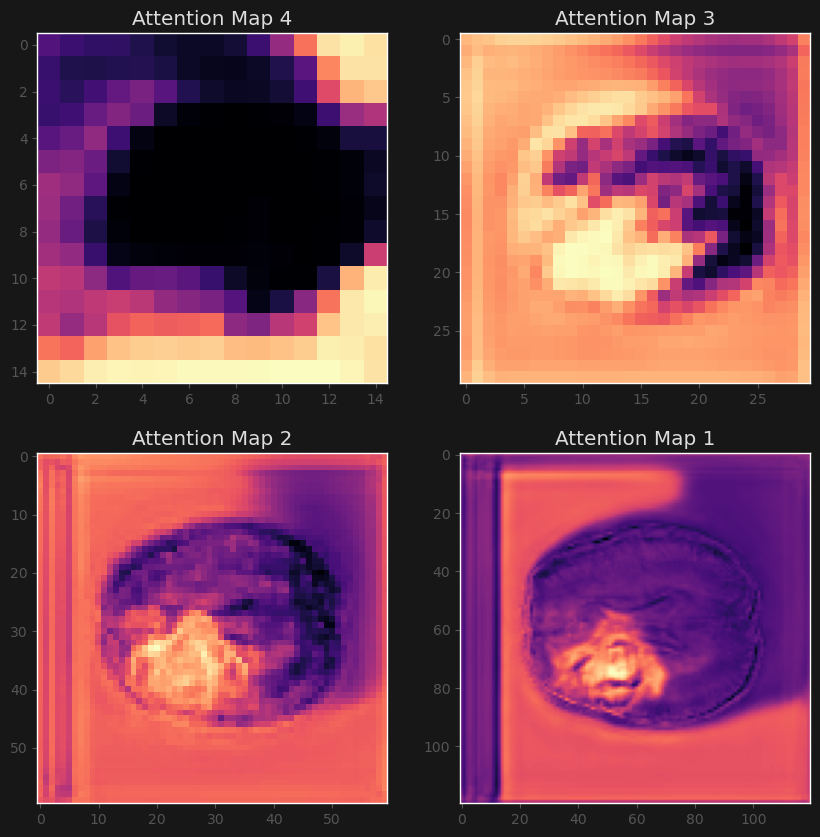

In [ ]:
# Build attention visualisation model, load to device then load trained weights
att_vis_unet = AttentionVisUNet().to(device)
att_vis_unet.load_state_dict(torch.load('attention-unet-weights.pth'))

# Forward pass to get attention maps
_, map_4, map_3, map_2, map_1 = att_vis_unet(test_input.to(device))

# Plot atttention maps
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for idx, (ax, att_map) in enumerate(zip(axes.flatten(), [map_4, map_3, map_2, map_1])):
    power = 2**(3 - idx)
    ax.imshow(att_map.detach().cpu().numpy().reshape(120//power,120//power), cmap='magma')
    ax.set_title(f'Attention Map {4-idx}')
    ax.grid(False)

#### Thoughts:
- The 4th attention map interestingly pays no attention to the brain itself, only the area surrounding it. This indicates that this residual pathway may not be very helpful.
- The 3rd map bas found the region the tumour is in, and looks like it's trying to ignore the healthy parts of the brain more than anything.
- Maps 1 and 2 both highlight the tumour more clearly, but also attends to areas of the background.